In [3]:
import sys
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(_root / "scripts"))

import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from glacier_utils import PROC, TAB, SIZE_LABELS, SIZE_COLORS, add_size_class, set_style, save_fig
set_style()

gdf = add_size_class(gpd.read_file(PROC / "nepal_glaciers.gpkg", layer="glaciers"))
hyp = pd.read_parquet(PROC / "nepal_hypsometry_km2.parquet").set_index("rgi_id")
bin_cols = sorted(hyp.columns, key=int)
hyp = hyp[bin_cols]
hyp.columns = hyp.columns.astype(int)              # column labels become integer bin centres (m)
centers = hyp.columns.to_numpy()                   # 50 m bin centres

core = gdf[gdf["centroid_in_nepal"]].set_index("rgi_id")   # primary dataset
H_core = hyp.loc[core.index]                                # km2 per 50 m bin
H_all = hyp.loc[gdf["rgi_id"]]                              # any overlap (sensitivity)

def to_100m(H):
    """Aggregate 50 m bins into 100 m bands (1600-1700, 1700-1800, ...); columns = band centres."""
    idx = (centers - 1600) // 100
    out = H.T.groupby(idx).sum().T
    out.columns = 1600 + out.columns.to_numpy() * 100 + 50
    return out

def wquantile(A50, q):
    """Area-weighted elevation quantile from a 50 m area series, interpolated inside the bin."""
    cum = A50.cumsum().to_numpy() / A50.sum()
    i = int(np.searchsorted(cum, q))
    prev = cum[i - 1] if i > 0 else 0.0
    return (centers[i] - 25) + 50 * (q - prev) / (cum[i] - prev)

print(f"Primary: {len(core):,} glaciers, {H_core.to_numpy().sum():,.1f} km2")
print(f"Any overlap: {len(H_all):,} glaciers, {H_all.to_numpy().sum():,.1f} km2")

Primary: 4,480 glaciers, 4,244.8 km2
Any overlap: 4,679 glaciers, 5,286.4 km2


In [4]:
A50 = H_core.sum()                  # regional area per 50 m bin
reg = to_100m(H_core).sum()         # regional area per 100 m band
total = A50.sum()

occ = A50[A50 > 0]
peak_band = reg.idxmax()
print(f"Elevation range with ice: {occ.index.min() - 25:.0f} to {occ.index.max() + 25:.0f} m")
print(f"Area-weighted elevation: 5th {wquantile(A50, .05):.0f} | median {wquantile(A50, .5):.0f} "
      f"| 95th {wquantile(A50, .95):.0f} m")
print(f"Peak area in the {peak_band - 50:.0f}-{peak_band + 50:.0f} m band: "
      f"{reg.max():.1f} km2 ({100 * reg.max() / total:.1f}% of area)")
print(f"Median of per-glacier zmed_m (each glacier counts once): {core['zmed_m'].median():.0f} m")

for z in (5000, 5500, 6000, 6500):
    print(f"Area above {z} m: {100 * A50[A50.index + 25 > z].sum() / total:.1f}%")

# Sensitivity: does including transboundary glaciers shift the regional median?
A50_all = H_all.sum()
print(f"\nSensitivity, area-weighted median elevation: primary {wquantile(A50, .5):.0f} m | "
      f"any overlap {wquantile(A50_all, .5):.0f} m")

pd.DataFrame({"area_km2_100m_band": reg, "pct_of_total": 100 * reg / total}).round(3).to_csv(
    TAB / "hypsometry_regional_100m.csv", index_label="band_centre_m")

Elevation range with ice: 2400 to 8700 m
Area-weighted elevation: 5th 4666 | median 5550 | 95th 6658 m
Peak area in the 5400-5500 m band: 316.6 km2 (7.5% of area)
Median of per-glacier zmed_m (each glacier counts once): 5450 m
Area above 5000 m: 86.4%
Area above 5500 m: 53.6%
Area above 6000 m: 21.8%
Area above 6500 m: 7.1%

Sensitivity, area-weighted median elevation: primary 5550 m | any overlap 5589 m


In [5]:
rows = []
for c in SIZE_LABELS:
    m = (core["size_class"] == c).to_numpy()
    A = H_core[m].sum()
    rows.append({
        "size_class": c, "n": int(m.sum()), "area_km2": A.sum(),
        "area_w_median_elev_m": wquantile(A, .5),
        "median_zmed_m": core.loc[m, "zmed_m"].median(),
        "median_zmin_m": core.loc[m, "zmin_m"].median(),
        "median_zmax_m": core.loc[m, "zmax_m"].median(),
        "median_elev_range_m": (core.loc[m, "zmax_m"] - core.loc[m, "zmin_m"]).median(),
    })
by_class = pd.DataFrame(rows).set_index("size_class")
print(by_class.round(0).to_string())
by_class.round(1).to_csv(TAB / "hypsometry_by_size_class.csv")

print("\nSpearman correlation of glacier area (log10) with elevation attributes:")
for col in ("zmin_m", "zmed_m", "zmax_m"):
    r, p = stats.spearmanr(np.log10(core["area_km2"]), core[col])
    print(f"  {col}: rho = {r:+.2f} (p = {p:.1e})")

               n  area_km2  area_w_median_elev_m  median_zmed_m  median_zmin_m  median_zmax_m  median_elev_range_m
size_class                                                                                                        
<0.5        3092     513.0                5435.0         5438.0         5248.0         5634.0                327.0
0.5–1        608     427.0                5445.0         5435.0         5091.0         5840.0                713.0
1–5          640    1325.0                5502.0         5466.0         4931.0         6104.0               1092.0
5–10          69     486.0                5518.0         5493.0         4666.0         6615.0               1998.0
10–50         67    1217.0                5726.0         5639.0         4458.0         7138.0               2688.0
>50            4     276.0                5818.0         5817.0         4546.0         7791.0               3143.0

Spearman correlation of glacier area (log10) with elevation attributes:
  zmin_

Saved outputs/figures/03_hypsometry_regional.png and .svg


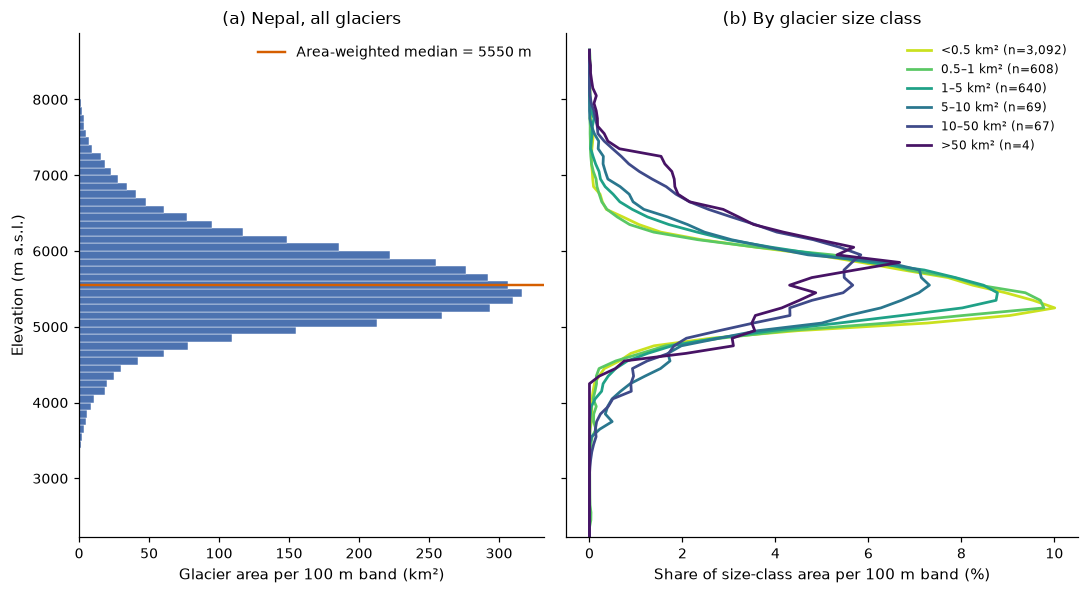

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5.5), sharey=True, gridspec_kw={"width_ratios": [1, 1.1]})

# (a) Regional area per 100 m band
ax1.barh(reg.index, reg.values, height=100, color="#4C72B0", edgecolor="white", linewidth=0.3)
med = wquantile(A50, .5)
ax1.axhline(med, color="#D55E00", lw=1.6, label=f"Area-weighted median = {med:.0f} m")
ax1.set_xlabel("Glacier area per 100 m band (km²)")
ax1.set_ylabel("Elevation (m a.s.l.)")
ax1.set_title("(a) Nepal, all glaciers")
ax1.legend(frameon=False, loc="upper right")

# (b) Share of each size class's own area per 100 m band
for c, col in zip(SIZE_LABELS, SIZE_COLORS):
    m = (core["size_class"] == c).to_numpy()
    r = to_100m(H_core[m]).sum()
    ax2.plot(100 * r / r.sum(), r.index, color=col, lw=1.8, label=f"{c} km² (n={m.sum():,})")
ax2.set_xlabel("Share of size-class area per 100 m band (%)")
ax2.set_title("(b) By glacier size class")
ax2.legend(frameon=False, loc="upper right", fontsize=8)

lo, hi = occ.index.min() - 200, occ.index.max() + 200
ax1.set_ylim(lo, hi)
fig.tight_layout()
save_fig(fig, "03_hypsometry_regional")
plt.show()

Saved outputs/figures/03_median_elevation_vs_size.png and .svg


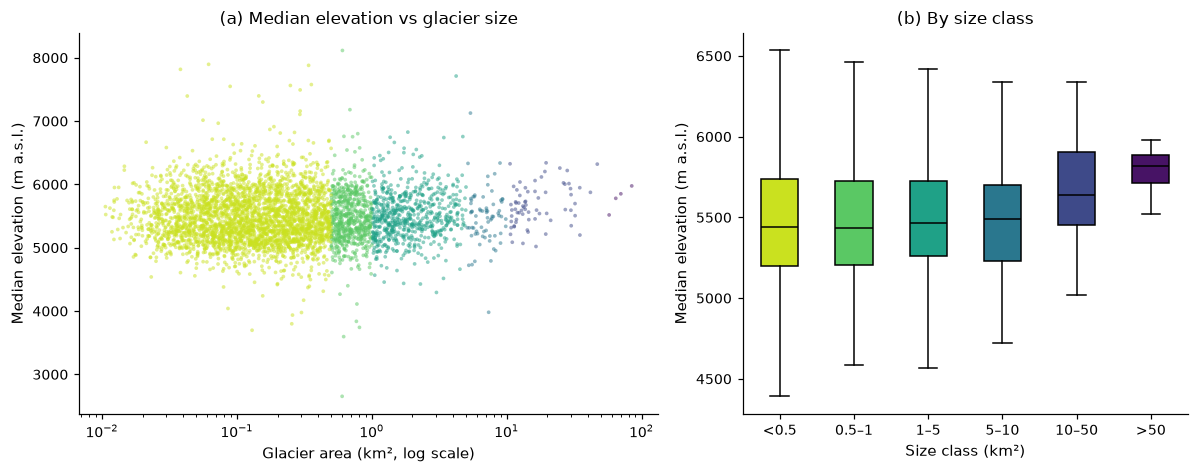

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})

colmap = dict(zip(SIZE_LABELS, SIZE_COLORS))
ax1.scatter(core["area_km2"], core["zmed_m"], c=core["size_class"].astype(str).map(colmap),
            s=6, alpha=0.5, linewidths=0, rasterized=True)
ax1.set_xscale("log")
ax1.set_xlabel("Glacier area (km², log scale)")
ax1.set_ylabel("Median elevation (m a.s.l.)")
ax1.set_title("(a) Median elevation vs glacier size")

data = [core.loc[core["size_class"] == c, "zmed_m"] for c in SIZE_LABELS]
bp = ax2.boxplot(data, patch_artist=True, showfliers=False, medianprops=dict(color="k"))
for patch, col in zip(bp["boxes"], SIZE_COLORS):
    patch.set_facecolor(col)
ax2.set_xticks(range(1, len(SIZE_LABELS) + 1), SIZE_LABELS)
ax2.set_xlabel("Size class (km²)")
ax2.set_ylabel("Median elevation (m a.s.l.)")
ax2.set_title("(b) By size class")

fig.tight_layout()
save_fig(fig, "03_median_elevation_vs_size")
plt.show()

In [9]:
cols = ["glac_name", "area_km2", "zmin_m", "zmax_m", "src_year", "dem_source"]

print("Five lowest-terminus glaciers:")
print(core.nsmallest(5, "zmin_m")[cols].reset_index().to_string(index=False))

print("\nThree highest glaciers:")
print(core.nlargest(3, "zmax_m")[cols].reset_index().to_string(index=False))

lo = A50[A50.index + 25 <= 4000].sum()
print(f"\nArea below 4000 m: {lo:.1f} km2 ({100 * lo / total:.2f}% of total)")

Five lowest-terminus glaciers:
                 rgi_id glac_name  area_km2    zmin_m    zmax_m  src_year dem_source
RGI2000-v7.0-G-15-04821       NaN  0.602240 2438.6710 3987.7537      1994   COPDEM30
RGI2000-v7.0-G-15-05144       NaN 32.141126 3082.3372 7105.9450      1994   COPDEM90
RGI2000-v7.0-G-15-05394       NaN  0.618352 3332.6487 4070.4775      1994   COPDEM30
RGI2000-v7.0-G-15-05101       NaN  3.012894 3403.5618 6272.5460      2010   COPDEM30
RGI2000-v7.0-G-15-05304       NaN  2.177897 3480.1702 6550.6040      1998   COPDEM30

Three highest glaciers:
                 rgi_id glac_name  area_km2    zmin_m   zmax_m  src_year dem_source
RGI2000-v7.0-G-15-08332       NaN  0.605395 7821.7180 8670.694      1999   COPDEM30
RGI2000-v7.0-G-15-08079       NaN  4.216974 6583.1494 8456.499      1994   COPDEM30
RGI2000-v7.0-G-15-07868    Yalung 64.349734 4363.4736 8431.870      1994   COPDEM90

Area below 4000 m: 27.3 km2 (0.64% of total)
